In [2]:
!unzip -q -o /content/*.zip -d /content
%cd /content/bank-marketing-ml-main/notebooks
!pip install -q -r ../requirements.txt
print("Setup done")

/content/bank-marketing-ml-main/notebooks
Setup done


# Member 2: Parts D and E
## Data preparation, preprocessing experiments and three base models

In [9]:
import warnings; warnings.filterwarnings("ignore")
import sys, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)


from src.config import FIG_DIR, RANDOM_STATE
from src import experiments as ex
from src.train import prepare_data, oof_probas, rank_models
from src.models import base_models, MODEL_LABELS
from src.preprocessing import make_pipeline, clean_and_engineer
from src.data_loading import split_xy
%matplotlib inline
print("Ready")

Ready


## Part D: Data preparation and feature engineering
### D1. Cleaning that is safe to do before the split (no learning from the data)
* drop 12 exact duplicates
* drop `duration` (target leakage: only known after the call)
* `default`: merge the 3 'yes' values into 'unknown'
* `pdays` -> `prev_contacted` flag (999 means "never contacted" for 96% of rows)
* `campaign` -> log(1 + campaign) to reduce skew

### D2. Steps learned from data (fitted inside the pipeline on training data only)
* 'unknown' kept as a category (or mode imputation, tested below)
* correlation filter (|Spearman rho| > 0.90)
* standard scaling
* one-hot encoding, with rare levels (< 30 rows) grouped as "infrequent"

In [4]:
raw, clean, X_tr, X_te, y_tr, y_te = prepare_data()
print("Raw:", raw.shape, "-> Cleaned:", clean.shape)
print("Train:", X_tr.shape, "positive rate %.4f" % y_tr.mean())
print("Test :", X_te.shape, "positive rate %.4f" % y_te.mean())
clean.head()

Raw: (41188, 21) -> Cleaned: (41176, 20)
Train: (32940, 19) positive rate 0.1127
Test : (8236, 19) positive rate 0.1127


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,age,campaign_log,previous,prev_contacted,emp_var_rate,cons_price_idx,cons_conf_idx,euribor3m,nr_employed,y
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent,56,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent,57,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent,37,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent,40,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent,56,0.693147,0,0,1.1,93.994,-36.4,4.857,5191.0,no


In [5]:
from sklearn.linear_model import LogisticRegression
demo = make_pipeline(LogisticRegression(max_iter=3000, class_weight="balanced"))
demo.fit(X_tr, y_tr)
cf = demo.named_steps["prep"].named_transformers_["num"].named_steps["corr_filter"]
print("Correlation filter dropped:", cf.dropped_)
print("Encoded feature count:", len(demo.named_steps["prep"].get_feature_names_out()))
demo

Correlation filter dropped: ['euribor3m', 'nr_employed']
Encoded feature count: 59


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('corr_filter',
                                                                   CorrelationFilter()),
                                                                  ('scale',
                                                                   StandardScaler())]),
                                                  ['age', 'campaign_log',
                                                   'previous', 'prev_contacted',
                                                   'emp_var_rate',
                                                   'cons_price_idx',
                                                   'cons_conf_idx', 'euribor3m',
                                                   'nr_employed']),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                                 min_frequency=30,
                                                                                 sparse_output=False))]),
                                                  ['job', 'marital',
                                                   'education', 'default',
                                                   'housing', 'loan', 'contact',
                                                   'month', 'day_of_week',
                                                   'poutcome'])],
                                   verbose_feature_names_out=False)),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=3000))])

### D3. Controlled preprocessing experiments
Each row changes ONE decision only. Scores are 5-fold stratified cross-validation on the training set.
PR-AUC is the main metric because only 11% of clients say yes.

In [6]:
t = time.time()
pre_exp = ex.preprocessing_experiments(X_tr, y_tr)
print(f"{time.time()-t:.0f}s")
pre_exp[["roc_auc","pr_auc","pr_auc_std","f1","recall","precision","fit_seconds"]]

184s


roc_auc  pr_auc  pr_auc_std      f1  recall  precision  fit_seconds
experiment        model variant                                                                                           
Unknown handling  LR    keep 'unknown' as category      0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          6.1
                        mode imputation                 0.7902  0.4441      0.0113  0.4481  0.6260     0.3490          4.9
                  HGB   keep 'unknown' as category      0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          5.6
                        mode imputation                 0.7913  0.4607      0.0176  0.4642  0.6147     0.3731          6.8
Imbalance         LR    none                            0.7892  0.4494      0.0135  0.3442  0.2323     0.6658          3.0
                        class weights                   0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          3.1
                        SMOTE                           0.7869  0.4402      0.0133  0.4381  0.6265     0.3368          4.6
                        random undersampling            0.7878  0.4415      0.0121  0.4417  0.6276     0.3408          4.0
                  HGB   none                            0.7941  0.4619      0.0173  0.3586  0.2479     0.6492          5.5
                        class weights                   0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          5.8
                        SMOTE                           0.7896  0.4509      0.0136  0.4035  0.3110     0.5753         19.0
                        random undersampling            0.7828  0.4307      0.0173  0.4321  0.6327     0.3281          5.3
Scaling           LR    standard scaling                0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          3.8
                        no scaling                      0.7870  0.4276      0.0108  0.4389  0.6333     0.3359         67.6
Feature selection LR    correlation filter |rho|>0.90   0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          4.6
                        all features                    0.7899  0.4460      0.0130  0.4504  0.6225     0.3529          3.4
                  HGB   correlation filter |rho|>0.90   0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          5.6
                        all features                    0.8005  0.4637      0.0160  0.4737  0.6233     0.3821          7.2
PCA               LR    no PCA                          0.7899  0.4440      0.0116  0.4488  0.6281     0.3492          3.1
                        PCA (95% variance)              0.7866  0.4283      0.0091  0.4286  0.6295     0.3249          2.5
                  HGB   no PCA                          0.7906  0.4599      0.0183  0.4653  0.6138     0.3748          7.2
                        PCA (95% variance)              0.7850  0.4365      0.0073  0.4601  0.6174     0.3668          4.8

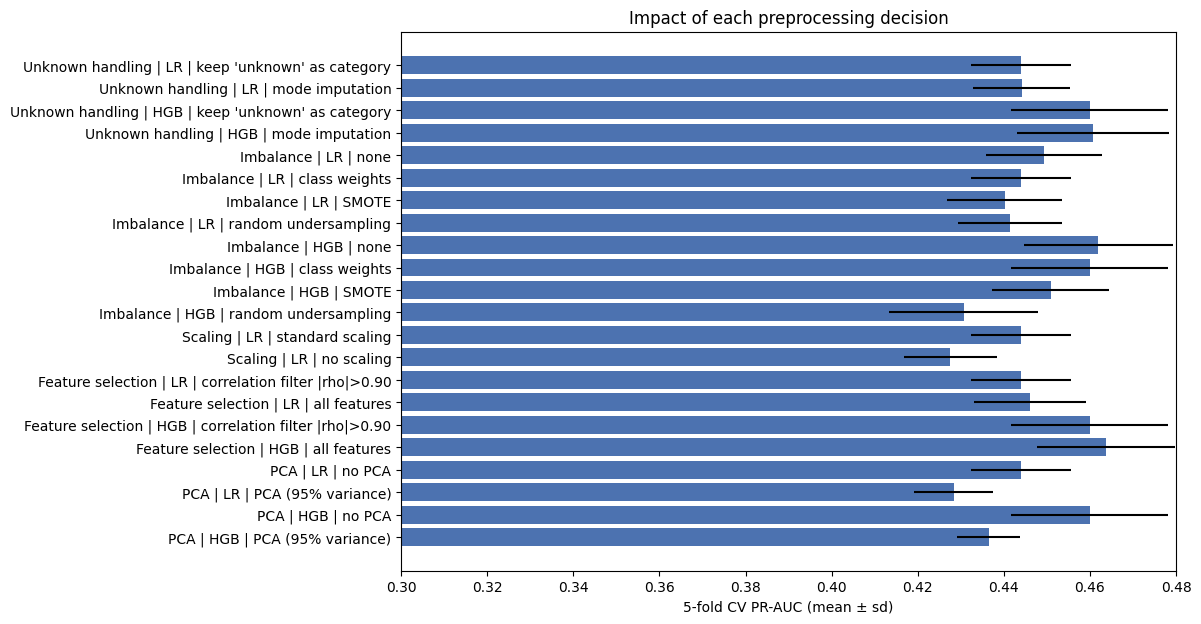

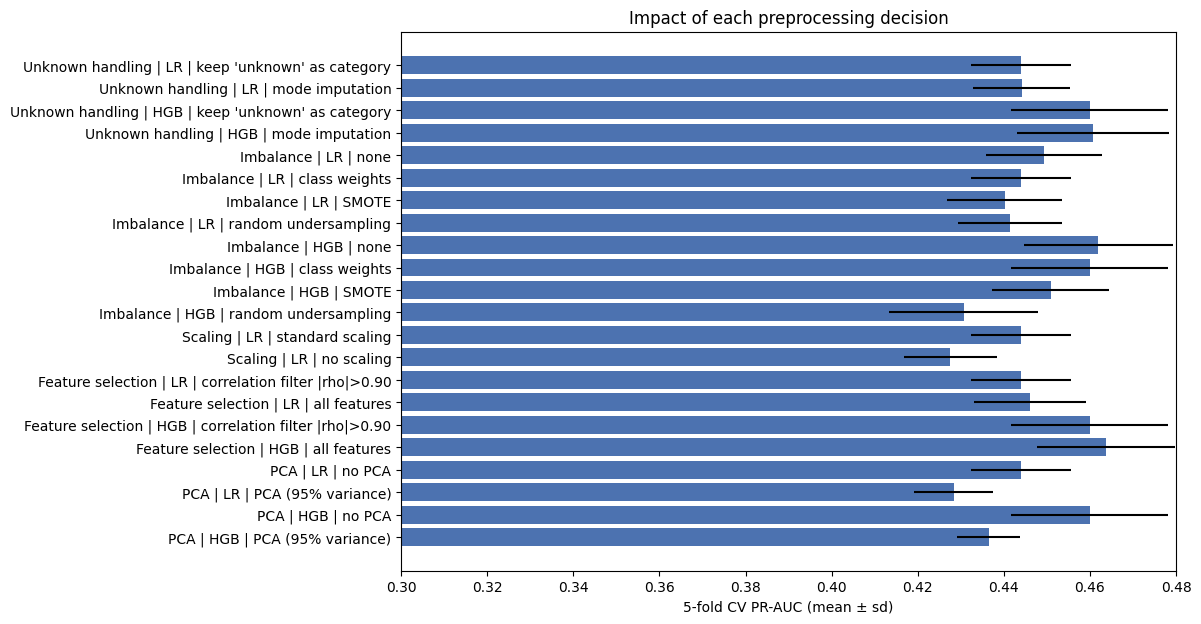

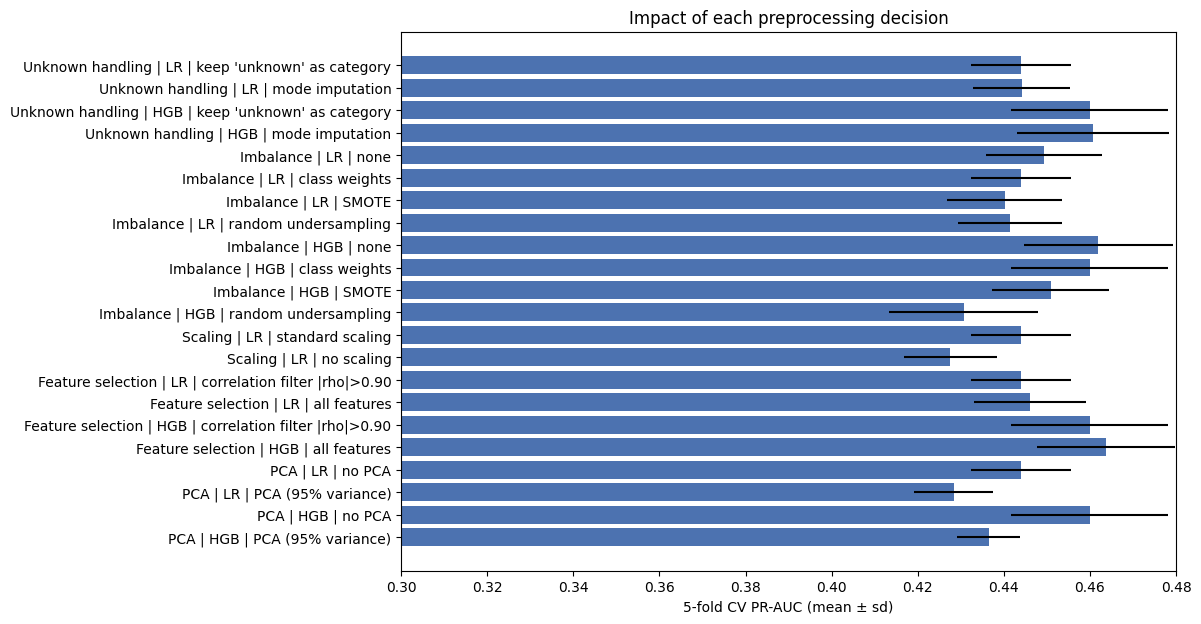

In [10]:
fig, ax = plt.subplots(figsize=(10, 7))
d = pre_exp.reset_index()
d["label"] = d["experiment"] + " | " + d["model"] + " | " + d["variant"]
ax.barh(d["label"], d["pr_auc"], xerr=d["pr_auc_std"], color=sns.color_palette("deep")[0])
ax.set_xlim(0.30, 0.48); ax.invert_yaxis(); ax.set_xlabel("5-fold CV PR-AUC (mean ± sd)")
ax.set_title("Impact of each preprocessing decision")
plt.show()

### D4. Leakage benchmark: what would happen if we kept duration?

In [11]:
clean_dur = clean_and_engineer(raw, drop_leakage=False)
Xd, yd = split_xy(clean_dur)
Xd_tr, yd_tr = Xd.loc[X_tr.index], yd.loc[X_tr.index]
leak = ex.leakage_benchmark(Xd_tr, yd_tr)
leak[["roc_auc","pr_auc","f1"]]

,roc_auc,pr_auc,f1
HGB without duration (deployable),0.7906,0.4599,0.4653
HGB with duration (leaky),0.9451,0.6510,0.6008


### D5. PCA explained variance and mutual information

59 encoded features; 27 principal components explain 95% of the variance


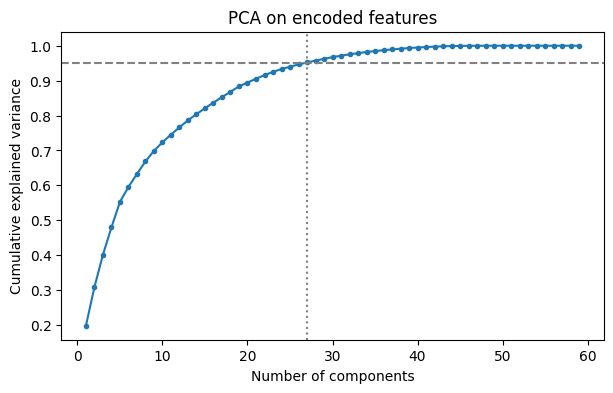

In [12]:
n_feat, cum = ex.pca_variance(X_tr)
k95 = int(np.searchsorted(cum, 0.95) + 1)
print(f"{n_feat} encoded features; {k95} principal components explain 95% of the variance")
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(cum) + 1), cum, marker=".")
ax.axhline(0.95, ls="--", color="grey"); ax.axvline(k95, ls=":", color="grey")
ax.set(xlabel="Number of components", ylabel="Cumulative explained variance", title="PCA on encoded features")
plt.show()

In [13]:
mi = ex.mutual_information(X_tr, y_tr)
mi.head(20).round(4)

,mutual_info
euribor3m,0.0724
cons_conf_idx,0.0675
cons_price_idx,0.0671
nr_employed,0.0614
emp_var_rate,0.0539
prev_contacted,0.0339
poutcome_success,0.0306
poutcome_nonexistent,0.0217
previous,0.0201
contact_cellular,0.0187


## Part E: Three base models
All three use the pipeline chosen in Part D and class weights for imbalance.
They are compared here with their DEFAULT settings; Member 3 tunes them in Part F.

| Model | Family | Why it is included |
|---|---|---|
| Logistic Regression | linear | simple, interpretable baseline |
| Random Forest | bagging of deep trees | non-linear, robust to outliers |
| Histogram Gradient Boosting | boosting of shallow trees | usually strongest on tabular data, fast |

In [14]:
models = base_models()
for name, pipe in models.items():
    print(MODEL_LABELS[name], "->", pipe.named_steps["model"])

Logistic Regression -> LogisticRegression(class_weight='balanced', max_iter=3000, random_state=42)
Random Forest -> RandomForestClassifier(class_weight='balanced_subsample', n_estimators=300,
                       n_jobs=-1, random_state=42)
Histogram Gradient Boosting -> HistGradientBoostingClassifier(class_weight='balanced', early_stopping=True,
                               n_iter_no_change=20, random_state=42)


In [15]:
oof_default = oof_probas(models, X_tr, y_tr)
baseline = rank_models(oof_default, y_tr)
baseline[["roc_auc","pr_auc","f1","mcc","recall","precision","capture_top20"]]

oof logreg: 5s
oof rf: 59s
oof hgb: 8s


,roc_auc,pr_auc,f1,mcc,recall,precision,capture_top20
hgb,0.7991,0.4648,0.4996,0.4315,0.5602,0.4508,0.6359
logreg,0.7897,0.4429,0.4814,0.4107,0.5362,0.4368,0.6246
rf,0.7743,0.4081,0.4555,0.3802,0.5354,0.3964,0.6001


### Summary of Parts D and E
Duplicates and the leaky `duration` column were removed (keeping duration inflates ROC-AUC from 0.79 to 0.95).
Controlled experiments chose: keep 'unknown' as a category, one-hot encoding, standard scaling,
a correlation filter for Logistic Regression only, and class weights for imbalance. PCA, SMOTE and
undersampling were rejected because each lowered PR-AUC.
With default settings, Gradient Boosting ranks first (PR-AUC 0.4648), Logistic Regression second (0.4429)
and Random Forest last (0.4081), because untuned Random Forest grows trees until they are pure and overfits.

**Hand-over to Member 3**
Pipeline: duplicates and duration dropped; prev_contacted and campaign_log added; 'unknown' kept as a category;
one-hot encoding with rare levels grouped; standard scaling; correlation filter for LR only; class weights;
no PCA, no SMOTE. Split: stratified 80/20, seed 42 (32,940 train / 8,236 test). Code: make_pipeline, base_models.

Baseline (5-fold CV on training set, default settings, run in Google Colab):
| Model | PR-AUC | ROC-AUC | F1 |
|---|---|---|---|
| Gradient Boosting | 0.4648 | 0.7991 | 0.4996 |
| Logistic Regression | 0.4429 | 0.7897 | 0.4814 |
| Random Forest | 0.4081 | 0.7743 | 0.4555 |

Random Forest looks overfitted with defaults (trees grown until pure), so it should gain most from tuning.